# 

In [10]:
import dgl.function as fn
from torch import nn
import torch
import torch.nn.functional as F
import copy
import pandas as pd
from src3.mol2graph import *
import pickle
from src3.polyG import *
import pickle
from torch.utils.data import DataLoader
from torch_geometric.data import Data, Dataset, InMemoryDataset
import torch
from dgl import DGLGraph
import dgl
import math

In [11]:
import pickle

with open('./data/polyG_for_tg.pkl','rb') as f:
    polyG=pickle.load(f)

In [12]:
test_df = pd.read_csv('./data/tg_test_df.csv')

In [13]:
mono_cache = dict()
missing_idx = []
for idx, pg in enumerate(test_df.psmiles):
    try:
        pg=pg.replace('Q', 'H').replace('R', 'H').replace('T','H').replace('*','H')
        mono_cache[idx] =  smiles_to_graph(pg)
    except:
        missing_idx.append(idx)

G:\miniconda3\envs\newHPG\lib\site-packages\dgl\heterograph.py:92: DGLWarning: Recommend creating graphs by `dgl.graph(data)` instead of `dgl.DGLGraph(data)`.
  dgl_warning(


In [14]:
mono_cache

{0: Graph(num_nodes=10, num_edges=28,
       ndata_schemes={'h': Scheme(shape=(49,), dtype=torch.float32)}
       edata_schemes={'e': Scheme(shape=(), dtype=torch.float32)}),
 1: Graph(num_nodes=9, num_edges=25,
       ndata_schemes={'h': Scheme(shape=(49,), dtype=torch.float32)}
       edata_schemes={'e': Scheme(shape=(), dtype=torch.float32)}),
 2: Graph(num_nodes=6, num_edges=16,
       ndata_schemes={'h': Scheme(shape=(49,), dtype=torch.float32)}
       edata_schemes={'e': Scheme(shape=(), dtype=torch.float32)}),
 3: Graph(num_nodes=1, num_edges=1,
       ndata_schemes={'h': Scheme(shape=(49,), dtype=torch.float32)}
       edata_schemes={'e': Scheme(shape=(), dtype=torch.float32)}),
 4: Graph(num_nodes=3, num_edges=7,
       ndata_schemes={'h': Scheme(shape=(49,), dtype=torch.float32)}
       edata_schemes={'e': Scheme(shape=(), dtype=torch.float32)}),
 5: Graph(num_nodes=4, num_edges=10,
       ndata_schemes={'h': Scheme(shape=(49,), dtype=torch.float32)}
       edata_schemes={'e'

In [15]:
def mono_from_df(processed_df):
    data_list = []

    for _idf in range(len(processed_df)):
        _df = processed_df.iloc[_idf]

        poly_key = _df.name

        # 1. 캐시에서 그래프 복제
        graph_data = mono_cache[poly_key].clone()

        # 2. 타깃값(Tg)을 텐서로 변환하여 직접 할당
        graph_data.y = torch.tensor([_df.tg_scaled], dtype=torch.float)

        # 3. 속성이 추가된 graph_data를 그대로 추가
        data_list.append(graph_data)

    return data_list

In [16]:
test_data_list = mono_from_df(test_df)

In [17]:
import dgl
import torch
import torch.nn as nn
import torch.nn.functional as F


class GAT(nn.Module):

    def __init__(self, in_feats, out_feats, edge_feats=1, num_heads=8, activation=None):
        super(GAT, self).__init__()
        self.num_heads = num_heads  # 인자로 받은 num_heads 사용
        self.out_feats = out_feats

        self.W_node = nn.Linear(in_feats, out_feats * num_heads, bias=False)
        self.W_edge = nn.Linear(edge_feats, num_heads, bias=False)
        self.attention_src = nn.Parameter(torch.Tensor(num_heads, out_feats))
        self.attention_dst = nn.Parameter(torch.Tensor(num_heads, out_feats))

        self.activation = activation
        self._init_weights()
    def _init_weights(self):
        nn.init.xavier_uniform_(self.W_node.weight)
        nn.init.xavier_uniform_(self.W_edge.weight)
        nn.init.xavier_uniform_(self.attention_src)
        nn.init.xavier_uniform_(self.attention_dst)
    def edge_attention(self, edges):
        src_feat = edges.src["h_trans"].view(
            -1, self.num_heads, self.out_feats
        )
        dst_feat = edges.dst["h_trans"].view(
            -1, self.num_heads, self.out_feats
        )
        edge_feat = edges.data["e_trans"].view(-1, self.num_heads, 1)

        # Attention score 계산
        attn = (
            torch.sum(src_feat * self.attention_src, dim=-1)
            + torch.sum(dst_feat * self.attention_dst, dim=-1)
            + edge_feat.squeeze(-1)
        )
        return {"e_attn": F.leaky_relu(attn)}

    def message_func(self, edges):
        weighted_msg = edges.src["h_trans"].view(
            -1, self.num_heads, self.out_feats
        ) * edges.data["alpha"].unsqueeze(-1)
        return {"m": weighted_msg}

    def reduce_func(self, nodes):
        h_new = torch.sum(nodes.mailbox["m"], dim=1)  # (N, num_heads, out_feats)
        return {"h_new": h_new.mean(dim=1)}  # multi-head 평균

    def forward(self, g, node_features):
        edge_features = g.edata["e"].reshape(-1, 1)
        g.ndata["h_trans"] = self.W_node(node_features)
        g.edata["e_trans"] = self.W_edge(edge_features)

        g.apply_edges(self.edge_attention)
        g.edata["alpha"] = dgl.nn.functional.edge_softmax(g, g.edata["e_attn"])
        g.update_all(self.message_func, self.reduce_func)

        h_final = g.ndata["h_new"]
        if self.activation is not None:
            h_final = self.activation(h_final)

        return h_final

In [18]:
class CollateSingleGraph:

    def __call__(self, sample):
        # 1. 단일 그래프 배치 병합
        bg = dgl.batch([s for s in sample])

        # 2. 이미 정규화된 y를 텐서로 병합
        y = torch.stack([s.y.squeeze() for s in sample], dim=0).reshape(-1, 1)

        return bg, y

In [19]:
test_loader = DataLoader(
    test_data_list,
    batch_size=512,
    shuffle=False,
    collate_fn=CollateSingleGraph(),
)

In [20]:
class GATNet(nn.Module):

    def __init__(self,in_dim=49,hidden_dim=256,pred_dim=1,depth=6,num_heads=8,dropout_rate=0.1,hidden_mode=False,):
        super().__init__()
        self.pred_dim = pred_dim
        self.depth = depth
        self.hidden_mode = hidden_mode
        self.activation = F.leaky_relu

        self.dims = [in_dim] + [hidden_dim] * self.depth

        # GAT 레이어 스택
        self.gat_layers = nn.ModuleList(
            [
                GAT(
                    self.dims[i],
                    self.dims[i + 1],
                    edge_feats=1,
                    num_heads=num_heads,
                    activation=self.activation,
                )
                for i in range(len(self.dims) - 1)
            ]
        )

        # Readout & Prediction MLP
        self.dropout = nn.Dropout(dropout_rate)
        self.linear_readout = nn.Linear(hidden_dim, 256)
        self.linear1 = nn.Linear(256, 128)
        self.linear2 = nn.Linear(128, pred_dim)

        self._init_mlp_weights()

    def _init_mlp_weights(self):
        for m in [self.linear_readout, self.linear1, self.linear2]:
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, g):
        # 1. 노드 초기 피처 추출
        h = g.ndata["h"]

        # 2. GAT Convolutions
        for gat in self.gat_layers:
            h = gat(g, h)
            h = self.dropout(h)

        g.ndata["h"] = h

        # 3. Readout (Graph-level Representation): Sum or Mean Pooling
        hg = dgl.sum_nodes(g, "h")  # (Batch_size, hidden_dim)
        hg = self.activation(self.linear_readout(hg))
        hg = self.dropout(hg)

        # 4. Regression Head
        hidden = self.activation(self.linear1(hg))
        hidden = self.dropout(hidden)

        if self.hidden_mode:
            return hidden

        out = self.linear2(hidden)  # (Batch_size, 1)
        return out

In [21]:
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. 디바이스 및 모델 초기화
device = torch.device("cpu")
model = GATNet().to(device)

# 2. Best 모델 가중치 로드
best_model_path = "ru_tg/model_best.bin"
model.load_state_dict(torch.load(best_model_path, map_location=device))
model.eval()
print(f"Loaded best model from: {best_model_path}\n")


# 3. 평가 함수 정의
def evaluate_loader(loader, model, device, dataset_name="Test"):
    preds_list = []
    labels_list = []

    with torch.no_grad():
        for batch in loader:
            if isinstance(batch, (list, tuple)):
                bg, label = batch
                label = label.to(device)
                labels_list.append(label.detach().cpu().numpy())
            else:
                bg = batch

            bg = bg.to(device)
            pred = model(bg)
            preds_list.append(pred.detach().cpu().numpy())

    preds_scaled = np.vstack(preds_list)
    preds_celsius = (preds_scaled * 92.34104534972987) + 331.15222534912186

    if labels_list:
        labels_scaled = np.vstack(labels_list)
        labels_celsius = (labels_scaled * 92.34104534972987) + 331.15222534912186

        mae = mean_absolute_error(labels_celsius, preds_celsius)
        rmse = np.sqrt(mean_squared_error(labels_celsius, preds_celsius))
        r2 = r2_score(labels_celsius, preds_celsius)

        print(f"--- [{dataset_name} Evaluation (℃)] ---")
        print(f"MAE  : {mae:.4f} K")
        print(f"RMSE : {rmse:.4f} K")
        print(f"R²   : {r2:.4f}\n")

        return preds_celsius, labels_celsius, (mae, rmse, r2)

    return preds_celsius, None, None


test_preds, test_labels, test_metrics = evaluate_loader(
    test_loader, model, device, "Test"
)

# 5. Test 결과 CSV 저장
if test_labels is not None:
    results_df = pd.DataFrame(
        {
            "Actual_Tg_K": test_labels.flatten(),
            "Pred_Tg_K": test_preds.flatten(),
            "Error": np.abs(test_labels.flatten() - test_preds.flatten()),
        }
    )
    results_df.to_csv(f"./RU_result.csv", index=False)

Loaded best model from: ru_tg/model_best.bin

--- [Test Evaluation (℃)] ---
MAE  : 22.7664 K
RMSE : 37.7723 K
R²   : 0.8135



MAE: 22.766, RMSE: 37.772, R2: 0.813


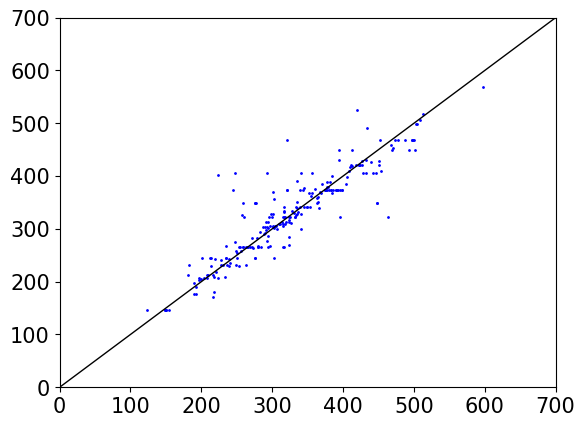

In [23]:
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn import metrics
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error
import matplotlib.pyplot as plt

ax = plt


ax.scatter(test_labels.flatten(),test_preds.flatten() , s=1,c='blue')
ax.tick_params(axis='both', labelsize=15)
plt.xlim(0, 700)
plt.ylim(0, 700)

ax.plot((0, 700), (0, 700), c="black", linewidth=1)

test_mae = mean_absolute_error(test_labels.flatten(),test_preds.flatten())
test_r2 = r2_score(test_labels.flatten(),test_preds.flatten())
test_rmse = root_mean_squared_error(test_labels.flatten(),test_preds.flatten())


print(f"MAE: {test_mae:.3f}, RMSE: {test_rmse:.3f}, R2: {test_r2:.3f}")

# 5. Test 결과 CSV 저장
if test_labels is not None:
    results_df = pd.DataFrame(
        {
            "Actual_Tg_K": test_labels.flatten(),
            "Pred_Tg_K": test_preds.flatten(),
        }
    )
    results_df.to_csv("./ru_result.csv", index=False)